## Тема 7. Основы нейронных сетей для распознавания изображений

---

### 1. Введение

Современные системы распознавания изображений в основном основаны на **искусственных нейронных сетях (Artificial Neural Networks, ANN)**.
Нейросети моделируют принципы работы биологических нейронов — элементов мозга, которые получают сигналы, обрабатывают их и принимают решения.

Нейронные сети хорошо решают задачи:

* классификации изображений (определение, что изображено);
* детектирования объектов (нахождение объектов на фото);
* сегментации (выделение областей на изображении);
* генерации изображений (создание новых образов).

---

### 2. Искусственный нейрон

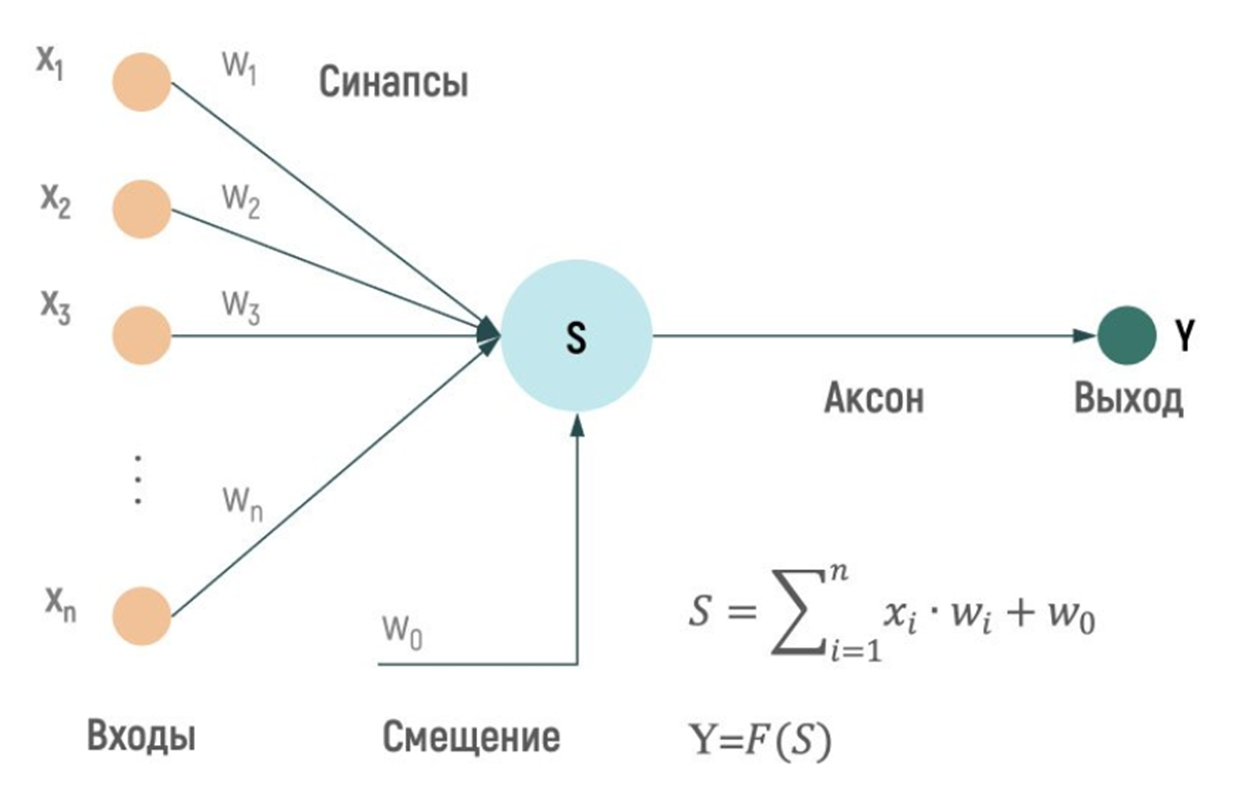

Базовый элемент сети — **искусственный нейрон**.
Он моделирует поведение биологического нейрона:
получает входные сигналы, умножает их на веса, суммирует, добавляет смещение и пропускает через **функцию активации**.

Формула работы нейрона: $$ y = f(\mathbf{w}^\top \mathbf{x} + b) $$

где:

* $\mathbf{x} = (x_1, x_2, ..., x_n)$ — входной вектор (признаки);
* $\mathbf{w} = (w_1, w_2, ..., w_n)$ — веса нейрона;
* $b$ — смещение (bias);
* $f(\cdot)$ — функция активации;
* $y$ — выход нейрона.

📘 **Интерпретация:**
Если сумма входов с весами превышает определённый порог, нейрон «активируется».

---

### 3. Модель персептрона

**Персептрон (Perceptron)** — простейшая нейронная модель, предложенная Ф. Розенблаттом (1958).
Он выполняет линейное разделение объектов на два класса.

Решающее правило:
$$
\hat{y} = \begin{cases}
1, & \text{если } \mathbf{w}^\top \mathbf{x} + b > 0, \
0, & \text{иначе.}
\end{cases}
$$

🔹 **Ограничение:**
Персептрон не способен решать *нелинейно разделимые* задачи (пример: логическая операция XOR).
Чтобы преодолеть это, используют **многослойные нейронные сети**.

---

### 4. Многослойный персептрон (MLP)

**Многослойный персептрон (Multi-Layer Perceptron, MLP)** — это сеть, состоящая из нескольких слоёв нейронов:

```
Вход → Скрытые слои → Выход
```

Каждый слой выполняет преобразование:
$$
\mathbf{h}^{(l)} = f(\mathbf{W}^{(l)} \mathbf{h}^{(l-1)} + \mathbf{b}^{(l)}),
$$
где $\mathbf{h}^{(l)}$ — выход (l)-го слоя.

Архитектура MLP:

* Входной слой — принимает признаки (например, пиксели изображения).
* Один или несколько скрытых слоёв — извлекают абстрактные признаки.
* Выходной слой — выдаёт вероятности классов.

📘 Пример:
Для классификации изображений 28×28 пикселей (MNIST) входной слой содержит 784 входа.

---

### 5. Функции активации

Функция активации делает модель **нелинейной**, что позволяет сети решать сложные задачи.

| Функция    | Формула                                                | Особенности                                                         |
| ---------- | ------------------------------------------------------ | ------------------------------------------------------------------- |
| Сигмоида   | $\sigma(z)=\frac{1}{1+e^{-z}}$                         | Исторически популярна, но медленно обучается (затухание градиентов) |
| tanh       | $\tanh(z)=\frac{e^z-e^{-z}}{e^z+e^{-z}}$               | Центрирована (значения -1…1)                                        |
| **ReLU**   | $\max(0, z)$                                           | Простая, эффективная, ускоряет обучение                             |
| Leaky ReLU | $\max(0.01z, z)$                                       | Устраняет проблему «мертвых» нейронов                               |
| Softmax    | $\text{softmax}(z_i) = \frac{e^{z_i}}{\sum_j e^{z_j}}$ | Используется на выходе для многоклассовой классификации             |

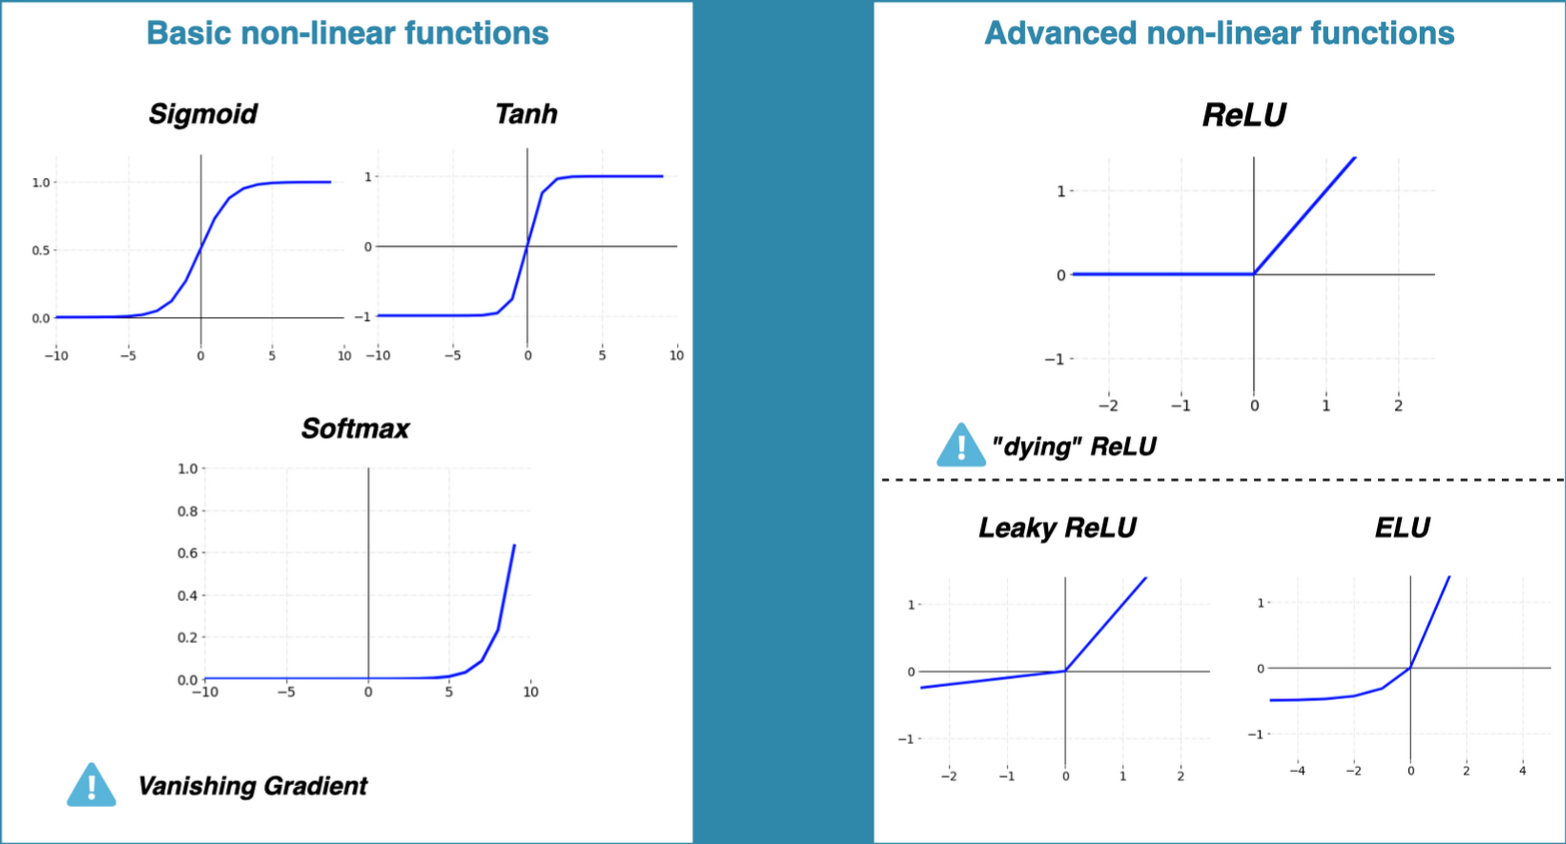

В скрытых слоях почти всегда используют ReLU.

В выходном — Softmax (если классов > 2) или Sigmoid (если классов = 2).

---

### 6. Функции потерь (Loss functions)

Функция потерь измеряет, насколько сильно предсказания модели отличаются от истинных значений.

Для классификации используется **кросс-энтропия**:
$$
L = - \sum_{i} y_i \log(\hat{y}_i)
$$
где:

* $y_i$ — истинная метка (в one-hot виде),
* $\hat{y}_i$ — предсказанная вероятность класса.

---

### 7. Обучение нейронной сети

#### 7.1. Прямое распространение (Forward pass)

* Вычисляется выход каждого слоя.
* В конце получаем предсказание $\hat{y}$.

#### 7.2. Обратное распространение ошибки (Backpropagation)

Используется для вычисления градиентов функции потерь по всем весам сети.
Основано на **правиле цепочки** из матанализа.

Идея: ошибка на выходе распределяется назад по слоям, и каждый слой корректирует свои веса.

#### 7.3. Обновление весов

Обновление происходит по правилу **градиентного спуска**:
$$
w_{ij}^{(t+1)} = w_{ij}^{(t)} - \eta \frac{\partial L}{\partial w_{ij}}
$$
где $\eta$ — скорость обучения (learning rate).

---

### 8. Оптимизаторы

Оптимизаторы — алгоритмы, которые управляют обновлением весов.

| Оптимизатор  | Суть                                                       | Особенности                       |
| ------------ | ---------------------------------------------------------- | --------------------------------- |
| **SGD**      | Простое обновление по градиенту                            | Требует подбора $\eta$            |
| **Momentum** | Добавляет инерцию (ускоряет движение в нужном направлении) | Сглаживает обучение               |
| **RMSProp**  | Масштабирует шаг по размеру градиента                      | Подходит для нестационарных задач |
| **Adam**     | Комбинация Momentum + RMSProp                              | Наиболее часто используемый       |

---

### 9. Регуляризация (борьба с переобучением)

Нейронные сети имеют много параметров → склонны к **overfitting**.
Основные методы борьбы:

| Метод                               | Суть                                                               |
| ----------------------------------- | ------------------------------------------------------------------ |
| **L2-регуляризация (weight decay)** | Добавление штрафа за большие веса                                  |
| **Dropout**                         | Случайное «отключение» нейронов во время обучения                  |
| **Early stopping**                  | Остановка обучения при росте ошибки на валидации                   |
| **Batch Normalization**             | Нормализация входов слоя → стабилизирует обучение                  |
| **Data Augmentation**               | Искусственное расширение обучающей выборки (повороты, сдвиги, шум) |

---

### 10. Инициализация весов

Правильная инициализация помогает избежать взрыва или затухания градиентов.

---

### 11. Метрики качества

Основные метрики для классификации изображений:

| Метрика                     | Описание                                                      |
| --------------------------- | ------------------------------------------------------------- |
| **Accuracy**                | Доля правильных классификаций                                 |
| **Precision / Recall / F1** | Для несбалансированных классов                                |
| **Confusion Matrix**        | Матрица ошибок: показывает, какие классы путаются между собой |

---

### 12. Пример обучения MLP на MNIST

1. Вход: 28×28 = 784 признаков.
2. Скрытый слой: 128 нейронов, ReLU.
3. Выход: 10 нейронов (классы 0–9), softmax.
4. Оптимизатор: Adam, learning rate = 0.001.
5. Функция потерь: cross-entropy.
6. Результат: точность ~97–98% после 10 эпох.

---

### 13. Проблемы MLP при работе с изображениями

Хотя MLP может распознавать простые изображения, у него есть недостатки:

* Не учитывает **пространственную структуру пикселей** (все пиксели рассматриваются независимо).
* Слишком много параметров при росте размера изображения.
* Плохо масштабируется на большие изображения.

🧩 **Решение:**
Использование **сверточных нейронных сетей (CNN)**, которые умеют работать с локальными признаками — это тема следующего занятия.

---

### 14. Ключевые выводы

1. Нейронные сети — это гибкие аппроксиматоры нелинейных функций.
2. Обучение основано на минимизации функции потерь методом обратного распространения ошибки.
3. Функции активации, инициализация и оптимизация играют решающую роль в успешном обучении.
4. Для изображений MLP ограничен — необходимы сверточные архитектуры.

---

статья с наглядными примерами: https://proglib.io/p/neural-network-course

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Загрузка MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

I0000 00:00:1791912473.973996  815769 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791912473.974377  815769 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791912474.001885  815769 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791912475.034744  815769 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

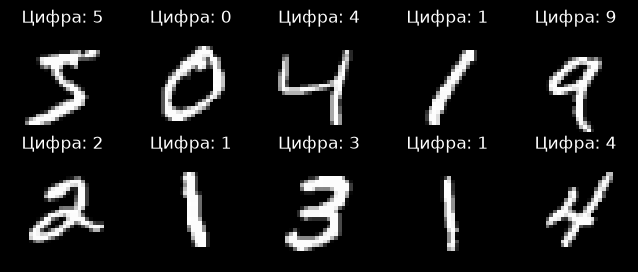

In [2]:
plt.figure(figsize=(8,3))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Цифра: {y_train[i]}")
    plt.axis("off")
plt.show()

In [3]:
# Создаём простую модель MLP:
# - Flatten: превращает 28x28 пикселей в вектор из 784 значений
# - Dense(128): скрытый слой с 128 нейронами и ReLU активацией
# - Dense(10): выходной слой с 10 нейронами (по одному на класс)

model = models.Sequential([
    layers.Input(shape=(28, 28)),       # входное изображение 28x28
    layers.Flatten(),                   # делаем "плоский" вектор признаков
    layers.Dense(128, activation='relu'),# скрытый слой
#    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax') # выходной слой (10 классов)
])

E0000 00:00:1791912476.230064  815769 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [4]:
# Посмотрим краткое описание модели
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# - Оптимизатор Adam — один из самых популярных
# - Функция потерь: sparse_categorical_crossentropy (т.к. метки — целые числа)
# - Метрика: точность (accuracy)
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [6]:
# Обучаем модель 5 эпох (можно увеличить до 10–20 для лучшего результата)
history = model.fit(
    x_train, y_train,
    validation_split=0.1,  # 10% данных используем для проверки
    epochs=5,
    batch_size=128,
    verbose=1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8940 - loss: 0.3794 - val_accuracy: 0.9502 - val_loss: 0.1795
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9477 - loss: 0.1829 - val_accuracy: 0.9658 - val_loss: 0.1298
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9618 - loss: 0.1325 - val_accuracy: 0.9712 - val_loss: 0.1057
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9707 - loss: 0.1022 - val_accuracy: 0.9748 - val_loss: 0.0923
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9770 - loss: 0.0817 - val_accuracy: 0.9770 - val_loss: 0.0847


In [7]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nТочность модели на тестовой выборке: {test_acc:.4f}")



Точность модели на тестовой выборке: 0.9739


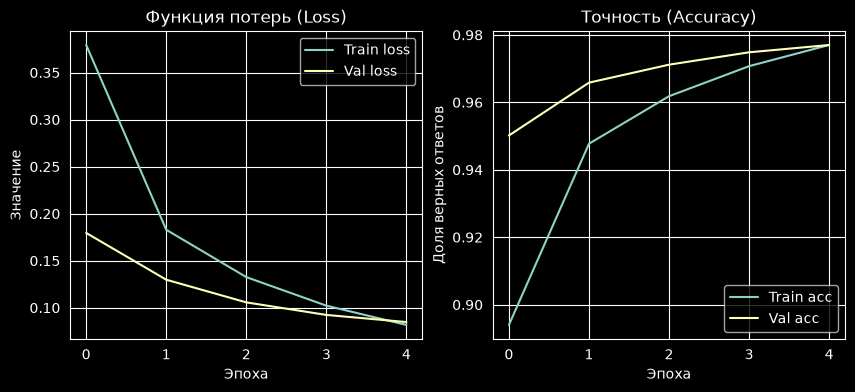

In [8]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Val loss')
plt.title("Функция потерь (Loss)")
plt.xlabel("Эпоха")
plt.ylabel("Значение")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Train acc')
plt.plot(history.history['val_accuracy'], label='Val acc')
plt.title("Точность (Accuracy)")
plt.xlabel("Эпоха")
plt.ylabel("Доля верных ответов")
plt.legend()

plt.show()

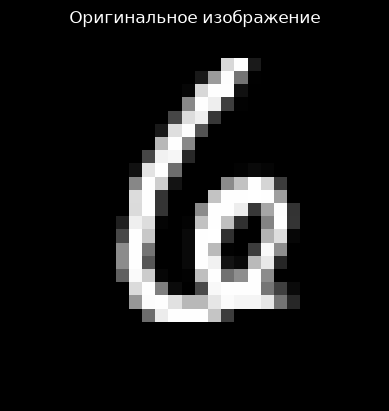

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
Модель предсказала: 6
Истинная метка: 6


In [9]:
import numpy as np

# Возьмём одно изображение из тестовой выборки
idx = 123
img = x_test[idx]
plt.imshow(img, cmap="gray")
plt.title("Оригинальное изображение")
plt.axis("off")
plt.show()

# Добавляем измерение batch (1, 28, 28)
img_input = np.expand_dims(img, axis=0)

# Предсказание
pred = model.predict(img_input)
predicted_label = np.argmax(pred)
print(f"Модель предсказала: {predicted_label}")
print(f"Истинная метка: {y_test[idx]}")

Возможные эксперименты:

Изменить число нейронов.
Добавить Dropout(0.3) после первого слоя — уменьшить переобучение. 
Попробовать больше эпох (10–15) — повысить точность.
Использовать оптимизатор SGD вместо Adam и сравнить скорость обучения.

/home/roma/PycharmProjects/university/.venv/lib/python3.14/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


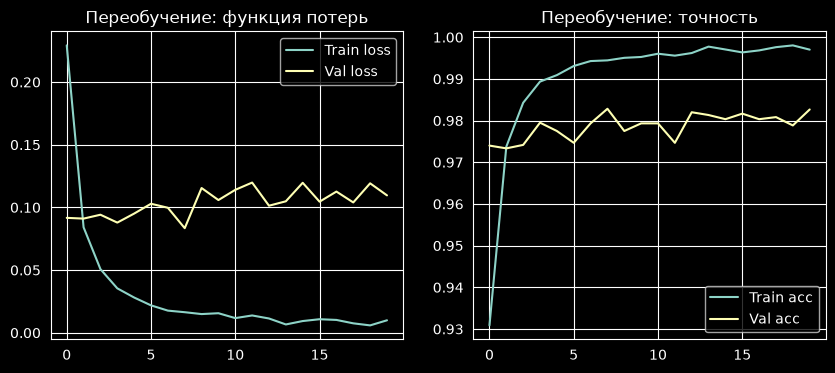

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Загружаем MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

# Слишком большая модель (переобучится)
model = models.Sequential([
    layers.Flatten(input_shape=(28,28)),
    layers.Dense(512, activation='relu'),
    layers.Dense(512, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Обучаем слишком долго
history = model.fit(x_train, y_train,
                    validation_split=0.1,
                    epochs=20, batch_size=128,
                    verbose=0)

# Графики
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Val loss')
plt.title("Переобучение: функция потерь")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Train acc')
plt.plot(history.history['val_accuracy'], label='Val acc')
plt.title("Переобучение: точность")
plt.legend()
plt.show()


Cеть зазубрила обучающую выборку, но потеряла способность обобщать.

Добавим Dropout(0.3) — отключаем 30% нейронов на каждой итерации.
Уменьшим количество эпох.
Модель чуть проще.

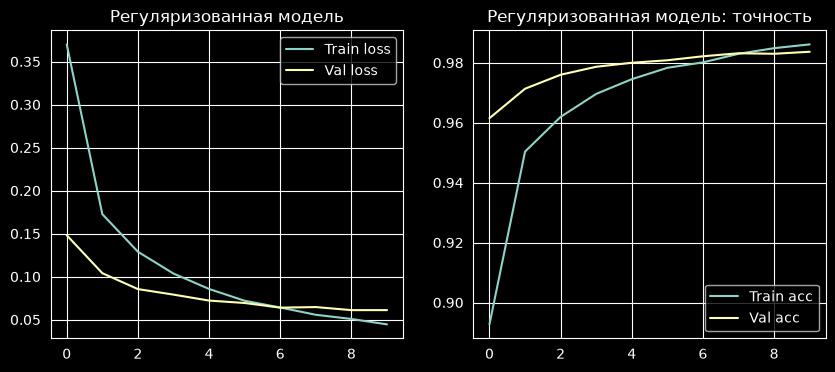

In [11]:
model2 = models.Sequential([
    layers.Flatten(input_shape=(28,28)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),   # <-- защита от переобучения
    layers.Dense(10, activation='softmax')
])

model2.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

history2 = model2.fit(x_train, y_train,
                      validation_split=0.1,
                      epochs=10, batch_size=128,
                      verbose=0)

# Графики
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history2.history['loss'], label='Train loss')
plt.plot(history2.history['val_loss'], label='Val loss')
plt.title("Регуляризованная модель")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history2.history['accuracy'], label='Train acc')
plt.plot(history2.history['val_accuracy'], label='Val acc')
plt.title("Регуляризованная модель: точность")
plt.legend()
plt.show()


Train accuracy растёт, но не достигает 100%

Val accuracy стабильно растёт и близка к train accuracy

Разрыв между ними ≤ 3–4%

Вывод: сеть учится обобщать, а не запоминать.

---

## Индивидуальные задания

1. Перебрать размер скрытого слоя (32 / 64 / 128 / 256 нейронов): построить график test accuracy от размера слоя и выписать число параметров из `model.summary()`. Когда рост слоя перестаёт окупаться?

2. Включить закомментированный `layers.Dropout(0.3)` в основную модель и обучить 5 эпох: изменились ли test accuracy и кривая val_loss? Помогает ли Dropout, когда переобучения ещё нет?

3. SGD vs Adam на одинаковой архитектуре (10 эпох): сравнить финальную точность, скорость сходимости по графику loss и время обучения (`time.perf_counter`).

4. *(Дополнительно)* Прогнать свои цифры (`digit_0.png`, `digit_1.png`) через обученный MLP тем же пайплайном, что и в занятии 6 (resize 28×28 → инверсия → нормализация → flatten). Узнаёт ли нейросеть то, что не узнал SVM?

---

## Задания для самостоятельной работы

1. **Ранняя остановка.** Обучить модель 30 эпох с `callbacks.EarlyStopping(patience=3, restore_best_weights=True)` — на какой эпохе обучение прервётся? Сравнить с ручным выбором числа эпох.

2. **Функции активации.** Заменить ReLU в скрытом слое на `sigmoid` и `tanh` — как меняется кривая loss по эпохам? Понаблюдать затухание градиентов у сигмоиды, о котором говорит теория (раздел 5).

3. **Learning rate.** Обучить с Adam при lr = 0.1 / 0.001 / 0.00001 (через `tf.keras.optimizers.Adam(learning_rate=...)`): три графика loss. Что происходит при слишком большом и слишком маленьком шаге?

4. **Batch size.** Обучить с batch_size = 32 / 128 / 1024: сравнить время одной эпохи и итоговую точность. В чём компромисс?


---

## Индивидуальная работа

In [12]:
import time
import numpy as np
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

### Задание 1. Подбор размера скрытого слоя

 32 нейронов: точность = 0.9526, параметров = 25450
 64 нейронов: точность = 0.9640, параметров = 50890
128 нейронов: точность = 0.9741, параметров = 101770
256 нейронов: точность = 0.9766, параметров = 203530


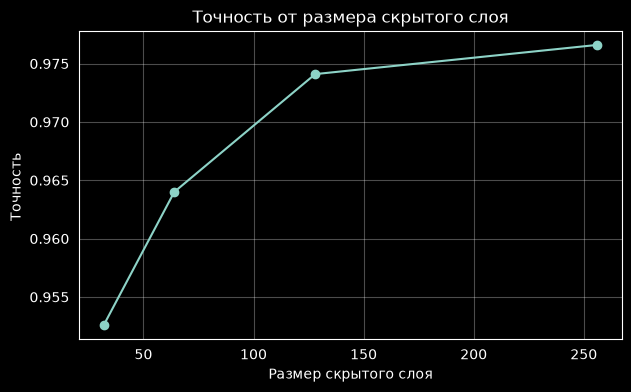

Прирост точности: [1.14 1.01 0.25] п.п.
Прирост параметров: [ 25440  50880 101760]


In [23]:
hidden_sizes = [32, 64, 128, 256]
acc, params = [], []
for h in hidden_sizes:
    m = models.Sequential([
        layers.Input(shape=(28, 28)),# Входной слой
        layers.Flatten(),   # Слой выравнивания.
        layers.Dense(h, activation='relu'), # Скрытый полносвязный слой h - колл нейронов
        layers.Dense(10, activation='softmax') # Выходной полносвязный слой.
    ])
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy']) # компиляция модели
    m.fit(x_train, y_train, epochs=5, batch_size=128, verbose=0) # обучение
    _, a = m.evaluate(x_test, y_test, verbose=0) # проверка
    acc.append(a)
    params.append(m.count_params())
    print(f"{h:3d} нейронов: точность = {a:.4f}, параметров = {m.count_params()}")

plt.figure(figsize=(7, 4))
plt.plot(hidden_sizes, acc, 'o-')
plt.xlabel("Размер скрытого слоя")
plt.ylabel("Точность ")
plt.title("Точность от размера скрытого слоя")
plt.grid(alpha=0.3)
plt.show()

print("Прирост точности:", np.round(np.diff(acc) * 100, 2), "п.п.")
print("Прирост параметров:", np.diff(params))

### Задание 2. Dropout в основной модели

без Dropout: test accuracy = 0.9723
Dropout 0.3: test accuracy = 0.9719


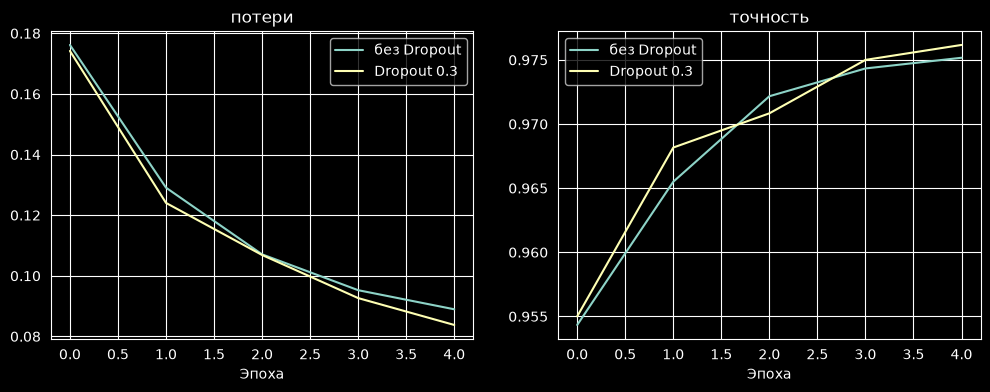

In [28]:
def build_mlp(hidden=128, dropout=None):
    layer_list = [layers.Input(shape=(28, 28)), layers.Flatten(),
                  layers.Dense(hidden, activation='relu')]
    if dropout:
        layer_list.append(layers.Dropout(dropout))
    layer_list.append(layers.Dense(10, activation='softmax'))
    return models.Sequential(layer_list)


histories = {}
for name, d in [("без Dropout", None), ("Dropout 0.3", 0.3)]:
    m = build_mlp(128, d)
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    histories[name] = m.fit(x_train, y_train, validation_split=0.1,
                            epochs=5, batch_size=128, verbose=0)
    _, a = m.evaluate(x_test, y_test, verbose=0)
    print(f"{name}: test accuracy = {a:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    ax[0].plot(h.history['val_loss'], label=name)
    ax[1].plot(h.history['val_accuracy'], label=name)
ax[0].set_title("потери"); ax[1].set_title("точность")
ax[0].set_xlabel("Эпоха"); ax[1].set_xlabel("Эпоха")
ax[0].legend(); ax[1].legend()
plt.show()

### Задание 3. SGD vs Adam

SGD: точность = 0.9230, время = 8.7 с
Adam: точность = 0.9764, время = 9.8 с


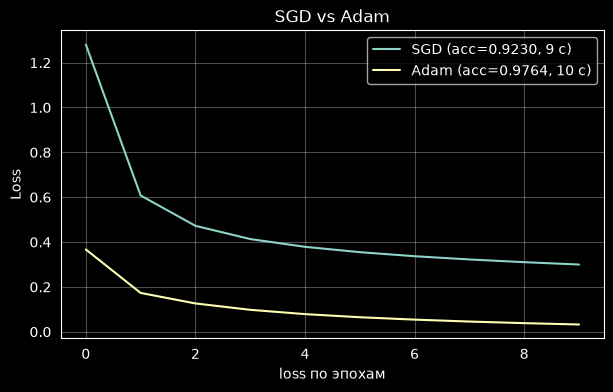

In [43]:
results = {}
for name, opt in [("SGD", tf.keras.optimizers.SGD()), ("Adam", tf.keras.optimizers.Adam())]:
    m = build_mlp(128)
    m.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    t0 = time.perf_counter()
    h = m.fit(x_train, y_train, validation_split=0.1, epochs=10, batch_size=128, verbose=0)
    dt = time.perf_counter() - t0
    _, a = m.evaluate(x_test, y_test, verbose=0)
    results[name] = (h, a, dt)
    print(f"{name}: точность = {a:.4f}, время = {dt:.1f} с")

plt.figure(figsize=(7, 4))
for name, (h, a, dt) in results.items():
    plt.plot(h.history['loss'], label=f"{name} (acc={a:.4f}, {dt:.0f} с)")

plt.xlabel("loss по эпохам")
plt.ylabel("Loss")
plt.title("SGD vs Adam"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Задание 4. Свои цифры через MLP

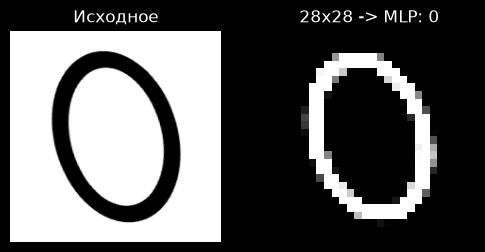

digit_0.png: предсказано 0


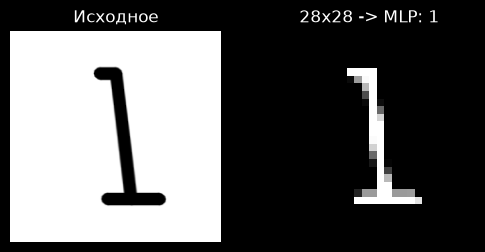

digit_1.png: предсказано 1


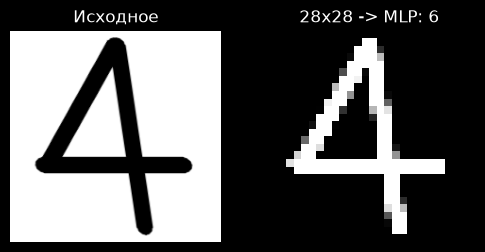

digit_4.png: предсказано 6


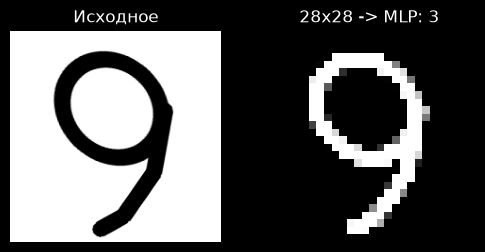

digit_9.png: предсказано 3


In [49]:
def predict_digit(path, model):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img28 = cv2.resize(img, (28, 28))
    img28 = 255 - img28
    x = (img28 / 255.0)[None, ...]
    return img, img28, int(np.argmax(model.predict(x, verbose=0)))


mlp = build_mlp(128)
mlp.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
mlp.fit(x_train, y_train, epochs=5, batch_size=128, verbose=0)

for path in ["digit_0.png","digit_1.png", "digit_4.png", "digit_9.png"]:
    img, img28, pred = predict_digit(path, mlp)
    fig, ax = plt.subplots(1, 2, figsize=(6, 3))
    ax[0].imshow(img, cmap="gray"); ax[0].set_title("Исходное"); ax[0].axis("off")
    ax[1].imshow(img28, cmap="gray"); ax[1].set_title(f"28x28 -> MLP: {pred}"); ax[1].axis("off")
    plt.show()
    print(f"{path}: предсказано {pred}")

## самостоятельная работа

### 1. Ранняя остановка

Обучение остановлено на эпохе 14 из 30
точность = 0.9765


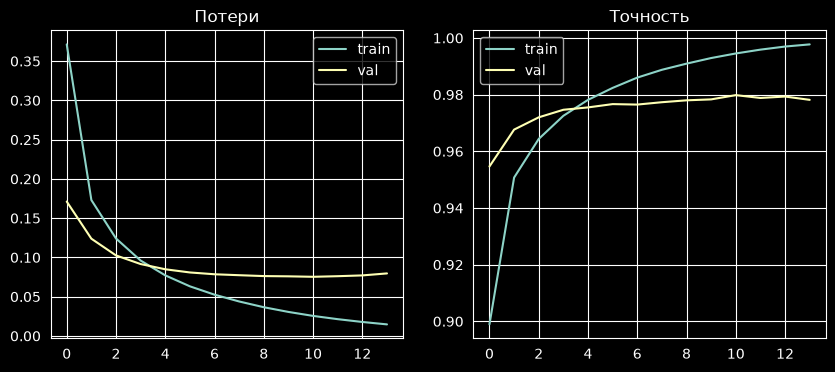

In [45]:
early = tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True) #  автоматической остановки обучения, как только модель перестает улучшаться.

m = build_mlp(128)

m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
h = m.fit(x_train, y_train, validation_split=0.1, epochs=30, batch_size=128,
          callbacks=[early], verbose=0)

_, a = m.evaluate(x_test, y_test, verbose=0)

print(f"Обучение остановлено на эпохе {len(h.history['loss'])} из 30")
print(f"точность = {a:.4f}")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(h.history['loss'], label='train')
plt.plot(h.history['val_loss'], label='val')
plt.title("Потери"); plt.legend()

plt.subplot(1, 2, 2)

plt.plot(h.history['accuracy'], label='train')
plt.plot(h.history['val_accuracy'], label='val')
plt.title("Точность"); plt.legend()
plt.show()

### 2. Функции активации

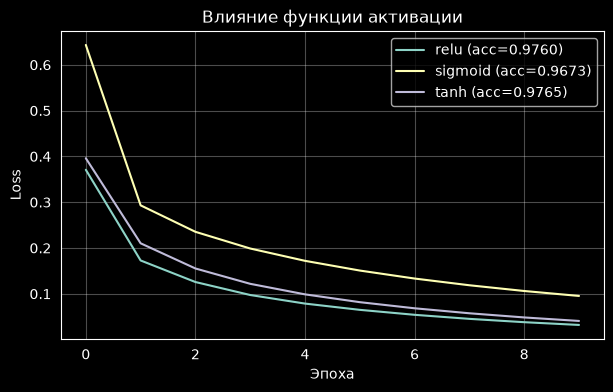

In [40]:
plt.figure(figsize=(7, 4))
for act in ['relu', 'sigmoid', 'tanh']:
    m = models.Sequential([
        layers.Input(shape=(28, 28)), layers.Flatten(),
        layers.Dense(128, activation=act),
        layers.Dense(10, activation='softmax')
    ])
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    h = m.fit(x_train, y_train, validation_split=0.1, epochs=10, batch_size=128, verbose=0)
    _, a = m.evaluate(x_test, y_test, verbose=0)
    plt.plot(h.history['loss'], label=f"{act} (acc={a:.4f})")

plt.xlabel("Эпоха"); plt.ylabel("Loss")
plt.title("Влияние функции активации"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

### 3. Learning rate

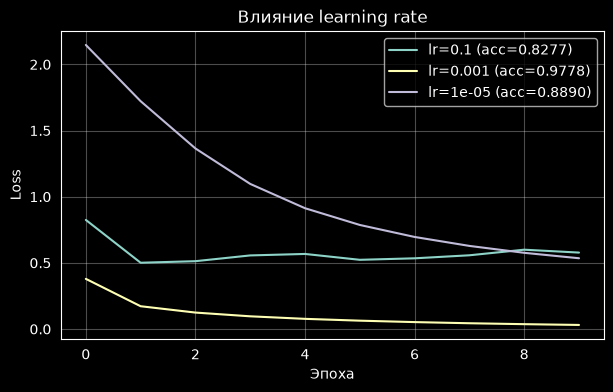

In [19]:
plt.figure(figsize=(7, 4))
for lr in [0.1, 0.001, 0.00001]:
    m = build_mlp(128)
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    h = m.fit(x_train, y_train, validation_split=0.1, epochs=10, batch_size=128, verbose=0)
    _, a = m.evaluate(x_test, y_test, verbose=0)
    plt.plot(h.history['loss'], label=f"lr={lr} (acc={a:.4f})")
plt.xlabel("Эпоха"); plt.ylabel("Loss")
plt.title("Влияние learning rate"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

### 4. Batch size

In [20]:
for bs in [32, 128, 1024]:
    m = build_mlp(128)
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    t0 = time.perf_counter()
    h = m.fit(x_train, y_train, epochs=5, batch_size=bs, verbose=0)
    dt = time.perf_counter() - t0
    _, a = m.evaluate(x_test, y_test, verbose=0)
    print(f"batch_size={bs:4d}: accuracy={a:.4f}, время 5 эпох={dt:.1f} с, время/эпоха={dt/5:.1f} с")

batch_size=  32: accuracy=0.9754, время 5 эпох=11.3 с, время/эпоха=2.3 с
batch_size= 128: accuracy=0.9736, время 5 эпох=4.8 с, время/эпоха=1.0 с
batch_size=1024: accuracy=0.9504, время 5 эпох=1.5 с, время/эпоха=0.3 с
